# 02 Spectral Visualization


In [ ]:
from pathlib import Path

def find_project_root(start=None):
    """Locate the project root from the working directory or an ancestor."""
    location = Path(start or Path.cwd()).resolve()
    for candidate in (location, *location.parents):
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Run Jupyter from the repository root or notebooks/ directory. The README.md and notebooks/ folder must exist.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
SPECTRA_DIR = PROJECT_ROOT / "spectra"
FIGURES_DIR = PROJECT_ROOT / "figures"
SAVE_FIGURES = False  # Figures render inline; optional exports disabled by default.
SAVE_TABLES = True    # Intermediate tables are required by downstream notebooks.
# Output folders are part of the repository layout; raw data remains private.


> **Saved spectra:** All available CO(1–0), CO(2–1), HNC, HCN and HCO⁺ plots from the original notebook are embedded below (three pointings for each transition). These are historical outputs and require the private input spectra to regenerate.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle


# ============================================================
# RUTAS GENERALES
# ============================================================

BASE_DIR = str(PROJECT_ROOT)

SPECTRA_DIR = os.path.join(BASE_DIR, "spectra")
FIGURES_DIR = os.path.join(BASE_DIR, "Figuras")
RESULTS_CLASS_DIR = os.path.join(BASE_DIR, "results", "ResultadosCLASS")

CO10_RESULTS_FILE = os.path.join(RESULTS_CLASS_DIR, "W_CO10_fit_results.dat")


# ============================================================
# CONSTANTES Y FRECUENCIAS
# ============================================================

C_LIGHT = 2.99792458e5  # km/s

# Velocidad sistémica de NGC 3110 usada como referencia global
VSYS_NGC3110 = 4990.0  # km/s

# Frecuencia central de las observaciones de gas denso
DENSE_SETUP_FREQ_GHZ = 88.4  # GHz

# Frecuencias de reposo J=1-0 en GHz
REST_FREQ_GHZ = {
    "HCN": 88.631847,
    "HCO": 89.188526,
    "HCO+": 89.188526,
    "HNC": 90.663568,
}


# ============================================================
# FUNCIONES DE LECTURA
# ============================================================

def read_fit_table(fit_file):
    """
    Lee una tabla de resultados de CLASS.

    Debe contener al menos:
    - fuente
    - linea

    Para usar velocidades debe contener:
    - Vcen_fit

    Para usar anchuras debe contener:
    - FWHM
    """
    df = pd.read_csv(fit_file, sep=r"\s+", engine="python")

    required_cols = ["fuente", "linea"]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Falta la columna '{col}' en {fit_file}")

    for col in ["Vcen_fit", "FWHM"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


def read_upperlimits_table(upperlimits_file):
    """
    Lee la tabla de límites superiores.

    Debe contener:
    - fuente
    - rms_mK
    - Delta_v_kms
    - delta_v_kms
    """
    df = pd.read_csv(upperlimits_file, sep=r"\s+", engine="python")

    required_cols = ["fuente", "rms_mK", "Delta_v_kms", "delta_v_kms"]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Falta la columna '{col}' en {upperlimits_file}")

    df = df[required_cols].copy()

    for col in ["rms_mK", "Delta_v_kms", "delta_v_kms"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


def get_vmed(results_df, fuente, linea):
    """
    Extrae Vcen_fit para una fuente y línea concretas.
    """
    if "Vcen_fit" not in results_df.columns:
        raise ValueError("La tabla no contiene la columna 'Vcen_fit'.")

    row = results_df[
        (results_df["fuente"] == fuente) &
        (results_df["linea"] == linea)
    ]

    if len(row) == 0:
        raise ValueError(f"No se encontró fuente='{fuente}' y linea='{linea}'")
    if len(row) > 1:
        raise ValueError(f"Hay varias filas para fuente='{fuente}' y linea='{linea}'")

    return float(row.iloc[0]["Vcen_fit"])


def get_FWHM(results_df, fuente, linea):
    """
    Extrae FWHM para una fuente y línea concretas.
    Devuelve None si no existe.
    """
    if "FWHM" not in results_df.columns:
        return None

    row = results_df[
        (results_df["fuente"] == fuente) &
        (results_df["linea"] == linea)
    ]

    if len(row) == 0:
        return None
    if len(row) > 1:
        raise ValueError(f"Hay varias filas de FWHM para fuente='{fuente}' y linea='{linea}'")

    value = row.iloc[0]["FWHM"]
    if pd.isna(value):
        return None

    return float(value)


def get_upperlimit_row(ul_df, fuente):
    """
    Extrae la fila de límite superior para una fuente.
    """
    row = ul_df[ul_df["fuente"] == fuente]

    if row.empty:
        raise ValueError(f"No hay fila en upperlimits para fuente='{fuente}'")
    if len(row) > 1:
        raise ValueError(f"Hay varias filas para fuente='{fuente}'")

    return row.iloc[0]


# ============================================================
# FUNCIONES PARA CORREGIR GAS DENSO
# ============================================================

def normalize_dense_line_key(linea):
    """
    Normaliza nombres de líneas de gas denso.
    Acepta HCN, HCO, HCO+, HNC.
    """
    s = str(linea).upper().replace(" ", "")

    if "HCO" in s:
        return "HCO+"
    if "HCN" in s:
        return "HCN"
    if "HNC" in s:
        return "HNC"

    raise ValueError(
        f"No reconozco la línea '{linea}'. Usa HCN, HCO/HCO+ o HNC."
    )


def get_rest_frequency_ghz(linea):
    """
    Devuelve la frecuencia de reposo de la línea en GHz.
    """
    key = normalize_dense_line_key(linea)
    return REST_FREQ_GHZ[key]


def compute_dense_redshifted_shift(
    linea,
    vsys=VSYS_NGC3110,
    nu_setup_ghz=DENSE_SETUP_FREQ_GHZ,
):
    """
    Calcula la traslación necesaria para que v=0 corresponda
    a la frecuencia redshifted de la línea concreta.

    No se recentra con CO(1-0). Es decir:
        v = 0  <=>  nu_obs = nu_rest / (1 + z_sys)

    Se asume que el eje original del .dat está referido a la
    frecuencia central del setup de gas denso, nu_setup_ghz.
    """

    nu_rest_ghz = get_rest_frequency_ghz(linea)

    z_sys = vsys / C_LIGHT
    nu_obs_ghz = nu_rest_ghz / (1.0 + z_sys)

    v_shift_kms = C_LIGHT * (
        nu_setup_ghz - nu_obs_ghz
    ) / nu_setup_ghz

    return {
        "v_shift_kms": float(v_shift_kms),
        "z_sys": float(z_sys),
        "nu_rest_ghz": float(nu_rest_ghz),
        "nu_obs_ghz": float(nu_obs_ghz),
        "nu_setup_ghz": float(nu_setup_ghz),
    }

In [ ]:
import matplotlib.transforms as mtransforms

# ============================================================
# FUNCION PARA LIMITAR EL RECTANGULO DE INTEGRACION
# ============================================================

def find_sigma_limits(x, y, vmed, smooth_n=3, sigma_factor=1.0):
    """
    Busca los límites izquierdo y derecho del perfil a partir de un umbral
    sigma_factor * sigma, usando una versión suavizada del espectro.

    sigma se estima a partir del propio espectro recortado.
    Si no encuentra límite por un lado, devuelve None en ese lado.
    """

    x = np.asarray(x)
    y = np.asarray(y)

    # sigma del ruido: estimación robusta con MAD
    med = np.nanmedian(y)
    mad = np.nanmedian(np.abs(y - med))
    sigma = 1.4826 * mad

    threshold = sigma_factor * sigma

    # suavizado simple
    if smooth_n is not None and smooth_n > 1:
        kernel = np.ones(smooth_n) / smooth_n
        y_work = np.convolve(y, kernel, mode="same")
    else:
        y_work = y.copy()

    # índice más cercano a vmed
    i0 = np.argmin(np.abs(x - vmed))

    # límite izquierdo
    low_vel = None
    for i in range(i0, 0, -1):
        if y_work[i] >= threshold and y_work[i - 1] < threshold:
            x1, x0 = x[i], x[i - 1]
            y1, y0 = y_work[i], y_work[i - 1]

            if y1 != y0:
                low_vel = x0 + (threshold - y0) * (x1 - x0) / (y1 - y0)
            else:
                low_vel = x0
            break

    # límite derecho
    high_vel = None
    for i in range(i0, len(x) - 1):
        if y_work[i] >= threshold and y_work[i + 1] < threshold:
            x0, x1 = x[i], x[i + 1]
            y0, y1 = y_work[i], y_work[i + 1]

            if y1 != y0:
                high_vel = x0 + (threshold - y0) * (x1 - x0) / (y1 - y0)
            else:
                high_vel = x1
            break

    return low_vel, high_vel, sigma


# ============================================================
# FUNCION PLOT DEL ESPECTRO
# ============================================================

def plot_spectrum_CO(
    dat_file,
    results_file,
    fuente,
    linea,
    line_label="CO(1-0)",
    source_name="NGC 3110",
    out_file=None,
    vel_lim=800,
    window_width=None,
    tmb_unit="mK",
    figsize=(8, 6),
    tick_fontsize=18,
    label_fontsize=22,
    title_fontsize=22,
    text_fontsize=12,
    vmed_min_fontsize=7,
):
    """
    Plotea el espectro de un .dat.
    Centra la figura en v=0.
    Destaca el área y marca con una flecha la velocidad media de la línea.

    El texto de v_med se coloca automáticamente fuera de la ventana verde:
    preferentemente a la izquierda; si no cabe bien, a la derecha.
    """

    # --------------------------------------------------
    # 1. Leer espectro
    # --------------------------------------------------
    spec = pd.read_csv(
        dat_file,
        sep=r"\s+",
        comment="#",
        names=["vel", "Tmb"],
        header=None,
        engine="python"
    )

    spec["vel"] = pd.to_numeric(spec["vel"], errors="coerce")
    spec["Tmb"] = pd.to_numeric(spec["Tmb"], errors="coerce")
    spec = spec.dropna(subset=["vel", "Tmb"]).reset_index(drop=True)

    # --------------------------------------------------
    # 2. Leer vmed y FWHM
    # --------------------------------------------------
    results_df = read_fit_table(results_file)
    vmed = get_vmed(results_df, fuente, linea)
    FWHM_value = get_FWHM(results_df, fuente, linea)
    
    # --------------------------------------------------
    # 3. Recortar espectro
    # --------------------------------------------------
    mask = (spec["vel"] >= -vel_lim) & (spec["vel"] <= vel_lim)
    x = spec.loc[mask, "vel"].to_numpy()
    y = spec.loc[mask, "Tmb"].to_numpy()

    if len(x) == 0:
        raise ValueError(f"No hay datos dentro de [{-vel_lim}, {vel_lim}] km/s")
    
    # --------------------------------------------------
    # 4. Ventana automática para detecciones
    # --------------------------------------------------
    low_vel, high_vel, _ = find_sigma_limits(
        x, y, vmed, smooth_n=3, sigma_factor=1.0
    )

    if low_vel is not None and high_vel is not None:
        low_vel, high_vel = min(low_vel, high_vel), max(low_vel, high_vel)

    if low_vel is None or high_vel is None:
        if window_width is None:
            if FWHM_value is None:
                raise ValueError(
                    "No se ha proporcionado window_width y no se pudo obtener FWHM automáticamente."
                )
            window_width = FWHM_value

        low_vel = vmed - window_width / 2.0
        high_vel = vmed + window_width / 2.0

    if len(x) > 1:
        dv = abs(np.nanmedian(np.diff(x)))
    else:
        dv = 0.0

    low_fill = low_vel - 0.5 * dv
    high_fill = high_vel + 0.5 * dv

    mask_int = (x >= low_fill) & (x <= high_fill)

    # --------------------------------------------------
    # 5. Preparar figura
    # --------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    ax.step(x, y, where="pre", linewidth=1.5, zorder=3)
    ax.axhline(0, color="k", linestyle="--", linewidth=1.1)

    y_min = np.nanmin(y)
    y_max = np.nanmax(y)
    dy = y_max - y_min if y_max > y_min else 1.0

    offset = 0.015 * dy

    # Flecha más corta y pequeña
    arrow_tip = -offset
    arrow_len = 0.07 * dy
    arrow_base = arrow_tip - arrow_len

    ax.arrow(
        vmed, arrow_base,
        0.0, arrow_len,
        head_width=12,
        head_length=0.20 * arrow_len,
        fc="k", ec="k",
        length_includes_head=True,
        zorder=5
    )

    # Ventana de integración
    ax.axvspan(low_fill, high_fill, facecolor="limegreen", alpha=0.5, zorder=0)

    # Relleno canal a canal dentro de la ventana
    if np.any(mask_int):
        ax.bar(
            x[mask_int],
            y[mask_int],
            width=dv,
            bottom=0.0,
            align="edge",
            alpha=0.8,
            edgecolor="none",
            zorder=2
        )

    title = f"{line_label} -- Pointing: {source_name}"
    title_color = "black"

    # --------------------------------------------------
    # 6. Texto de vmed: arriba a la izquierda, pequeño
    # --------------------------------------------------

    text_str = rf"$\uparrow\ v_{{\rm med}} = {vmed:.1f}\ \mathrm{{km\ s^{{-1}}}}$"

    fontsize_now = text_fontsize

    vmed_text = ax.text(
        0.02,
        0.95,
        text_str,
        transform=ax.transAxes,
        fontsize=fontsize_now,
        ha="left",
        va="top",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=1.5
        ),
        zorder=10
    )

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    ax_bbox = ax.get_window_extent(renderer=renderer)
    max_width = ax_bbox.width * 0.70

    while fontsize_now > vmed_min_fontsize:
        text_bbox = vmed_text.get_window_extent(renderer=renderer)

        if text_bbox.width <= max_width:
            break

        fontsize_now -= 1
        vmed_text.set_fontsize(fontsize_now)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

    # --------------------------------------------------
    # 7. Ejes
    # --------------------------------------------------
    ax.set_xlim(-vel_lim, vel_lim)

    ax.set_xlabel(
        r"Velocity [km s$^{-1}$]",
        fontsize=label_fontsize,
        labelpad=10
    )

    ax.set_ylabel(
        rf"$T_{{\rm MB}}$ [{tmb_unit}]",
        fontsize=label_fontsize,
        labelpad=10
    )

    ax.set_title(
        title,
        fontsize=title_fontsize,
        color=title_color,
        pad=14
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        width=1.4,
        length=6
    )

    ax.tick_params(
        axis="both",
        which="minor",
        width=1.0,
        length=3
    )

    fig.tight_layout()

    # --------------------------------------------------
    # 8. Guardar
    # --------------------------------------------------
    if out_file is not None:
        out_dir = os.path.dirname(out_file)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        if SAVE_FIGURES: fig.savefig(out_file, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

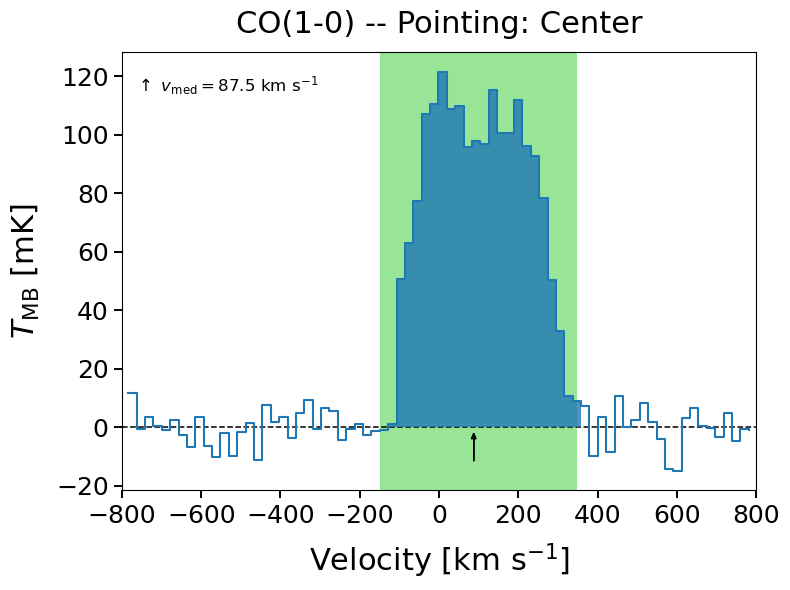

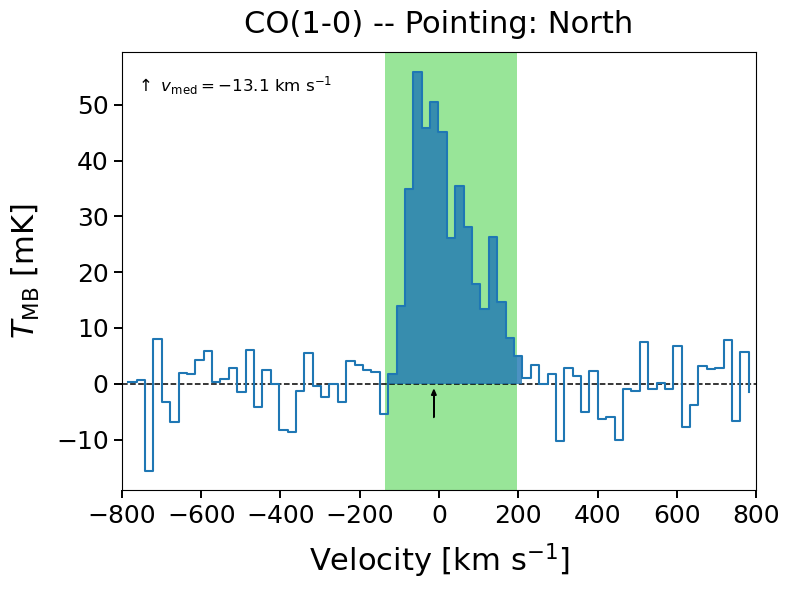

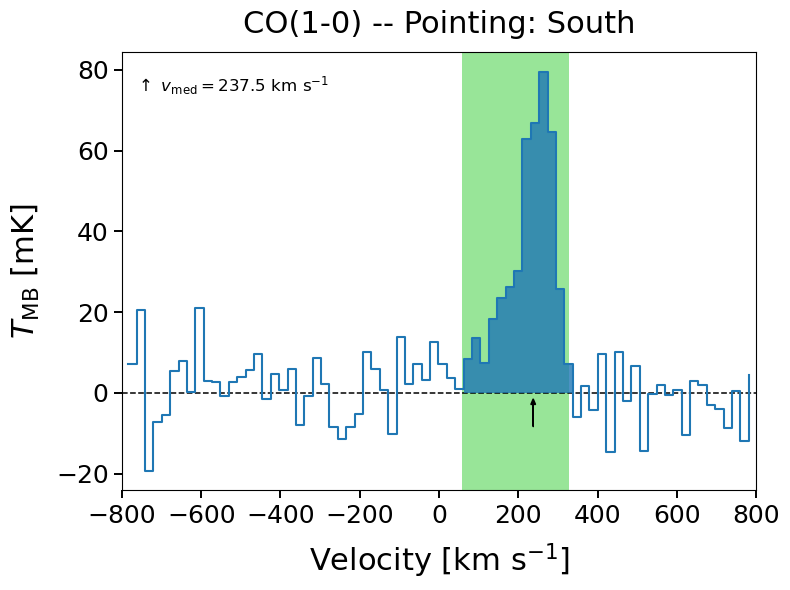

In [3]:
plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_CCO10_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO10_fit_results.dat'),
    fuente="NGC3110_CEN",
    linea="12CO10_6",
    line_label="CO(1-0)",
    source_name="Center",
    out_file=str(PROJECT_ROOT / 'Figuras/CEN_CO10.png'),
    vel_lim=800,
    tmb_unit="mK"
)

plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_NCO10_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO10_fit_results.dat'),
    fuente="NGC3110_NOR",
    linea="12CO10_6",
    line_label="CO(1-0)",
    source_name="North",
    out_file=str(PROJECT_ROOT / 'Figuras/NOR_CO10.png'),
    vel_lim=800,
    tmb_unit="mK"
)

plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_SCO10_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO10_fit_results.dat'),
    fuente="NGC3110_SOU",
    linea="12CO10_6",
    line_label="CO(1-0)",
    source_name="South",
    out_file=str(PROJECT_ROOT / 'Figuras/SOU_CO10.png'),
    vel_lim=800,
    tmb_unit="mK"
)

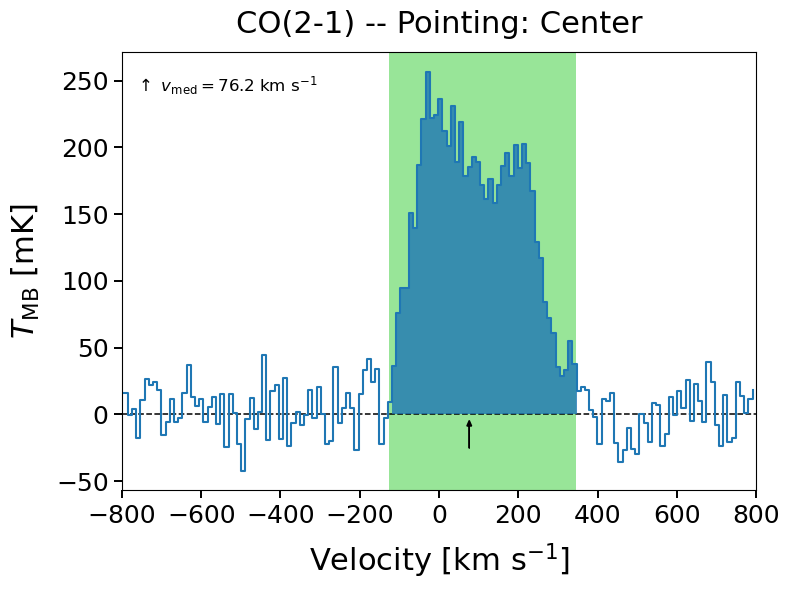

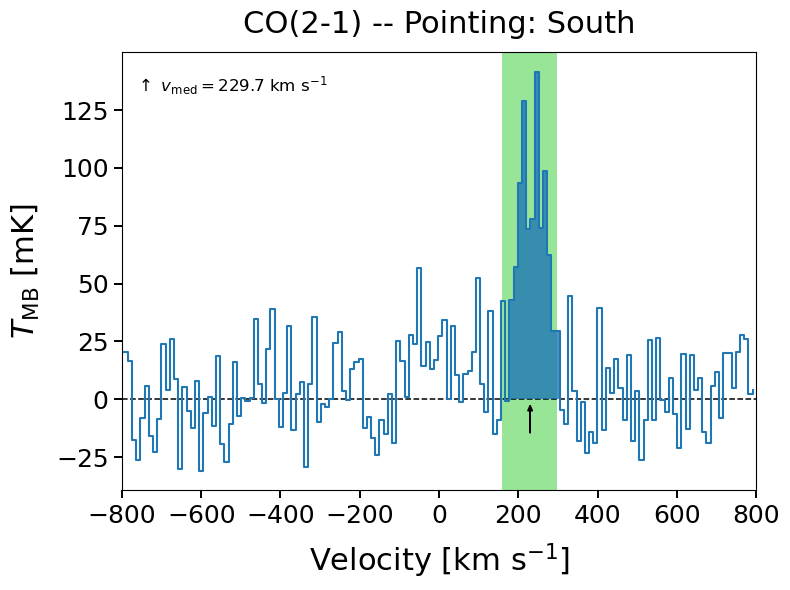

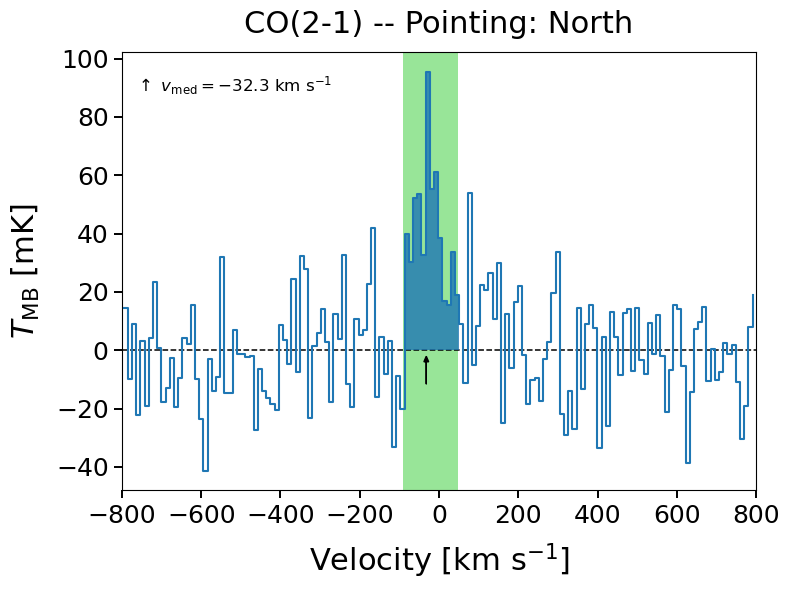

In [4]:
plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_CCO21_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO21_fit_results.dat'),
    fuente="NGC3110_CEN",
    linea="12CO21_5",
    line_label="CO(2-1)",
    source_name="Center",
    out_file=str(PROJECT_ROOT / 'Figuras/CEN_CO21.png'),
    vel_lim=800,
    tmb_unit="mK"
)

plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_SCO21_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO21_fit_results.dat'),
    fuente="NGC3110_SOU",
    linea="12CO21_5",
    line_label="CO(2-1)",
    source_name="South",
    out_file=str(PROJECT_ROOT / 'Figuras/SOU_CO21.png'),
    vel_lim=800,
    tmb_unit="mK"
)

plot_spectrum_CO(
    dat_file=str(PROJECT_ROOT / 'spectra/W_NCO21_spectrum.dat'),
    results_file=str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO21_fit_results.dat'),
    fuente="NGC3110_NOR",
    linea="12CO21_5",
    line_label="CO(2-1)",
    source_name="North",
    out_file=str(PROJECT_ROOT / 'Figuras/NOR_CO21.png'),
    vel_lim=800,
    tmb_unit="mK"
)

In [ ]:
# ============================================================
# FUNCION PLOT DEL ESPECTRO DE GAS DENSO
# ============================================================

def plot_spectrum_Dense(
    dat_file,
    results_file,
    fuente,
    linea,
    line_label="Dense gas",
    source_name="NGC 3110",
    out_file=None,
    delta_vel=800,
    window_width=None,
    detected="yes",
    upperlimits_file=None,
    co_results_file=CO10_RESULTS_FILE,
    co_linea="12CO10_6",
    vsys=VSYS_NGC3110,
    nu_setup_ghz=DENSE_SETUP_FREQ_GHZ,
    tmb_unit="mK",
    figsize=(8, 6),
    extra_ch_left=0,
    extra_ch_right=0,
    tick_fontsize=18,
    label_fontsize=22,
    title_fontsize=22,
    text_fontsize=12,
    show_gaussian_arrow=True,
    show_delta_v_text=True,
):
    """
    Plotea espectros de gas denso usando como referencia la frecuencia
    redshifted de cada línea.

    Criterio usado:
        v = 0 corresponde a la frecuencia redshifted de la transición
        representada: HCN(1-0), HCO+(1-0) o HNC(1-0).

    Importante:
    -----------
    No se recentra el eje de velocidades con CO(1-0). Por tanto, las líneas
    de un mismo pointing deben aparecer aproximadamente a la misma velocidad,
    pero no necesariamente centradas en v = 0.
    """

    detected = detected.strip().lower()

    if detected not in ["yes", "no"]:
        raise ValueError("El argumento detected debe ser 'yes' o 'no'.")

    # --------------------------------------------------
    # 1. Leer espectro
    # --------------------------------------------------
    spec = pd.read_csv(
        dat_file,
        sep=r"\s+",
        comment="#",
        names=["vel", "Tmb"],
        header=None,
        engine="python"
    )

    spec["vel"] = pd.to_numeric(spec["vel"], errors="coerce")
    spec["Tmb"] = pd.to_numeric(spec["Tmb"], errors="coerce")
    spec = spec.dropna(subset=["vel", "Tmb"]).reset_index(drop=True)

    # --------------------------------------------------
    # 2. Eje de velocidad centrado en la frecuencia redshifted de la línea
    # --------------------------------------------------
    shift_info = compute_dense_redshifted_shift(
        linea=linea,
        vsys=vsys,
        nu_setup_ghz=nu_setup_ghz,
    )

    v_shift = shift_info["v_shift_kms"]

    spec["vel_plot"] = spec["vel"] - v_shift
    spec = spec.sort_values("vel_plot").reset_index(drop=True)

    # --------------------------------------------------
    # 3. Información de la detección
    # --------------------------------------------------
    vmed_dense_plot = None
    delta_v_dense = None
    integration_center = None

    if detected == "yes":
        if results_file is None:
            raise ValueError("Para detected='yes', debes proporcionar results_file.")

        results_df = read_fit_table(results_file)

        FWHM_value = get_FWHM(results_df, fuente, linea)
        vmed_dense_raw = get_vmed(results_df, fuente, linea)

        if vmed_dense_raw is not None and np.isfinite(vmed_dense_raw):
            vmed_dense_plot = vmed_dense_raw - v_shift
            delta_v_dense = vmed_dense_plot
            integration_center = vmed_dense_plot

        if window_width is None:
            if FWHM_value is None:
                raise ValueError(
                    "Para detecciones debes proporcionar window_width "
                    "o tener FWHM en la tabla de resultados."
                )
            window_width = FWHM_value

        if integration_center is None:
            raise ValueError(
                "No se ha podido determinar el centro de integración de la línea."
            )

    # --------------------------------------------------
    # 4. Recortar espectro
    # --------------------------------------------------
    mask = (
        (spec["vel_plot"] >= -delta_vel) &
        (spec["vel_plot"] <= delta_vel)
    )

    x = spec.loc[mask, "vel_plot"].to_numpy()
    y = spec.loc[mask, "Tmb"].to_numpy()

    if len(x) == 0:
        raise ValueError(
            f"No hay datos dentro de [{-delta_vel}, {delta_vel}] km/s "
            f"después de recentrar en la frecuencia redshifted de {linea}."
        )

    dv = abs(np.nanmedian(np.diff(x))) if len(x) > 1 else 0.0

    # --------------------------------------------------
    # 5. Ventana de integración o límite superior
    # --------------------------------------------------
    if detected == "yes":
        low_fill = integration_center - window_width / 2.0 - (0.5 + extra_ch_left) * dv
        high_fill = integration_center + window_width / 2.0 + (0.5 + extra_ch_right) * dv

        mask_int = (x >= low_fill) & (x <= high_fill)

    else:
        if upperlimits_file is None:
            raise ValueError("Si detected='no', debes proporcionar upperlimits_file.")

        ul_df = read_upperlimits_table(upperlimits_file)
        ul_row = get_upperlimit_row(ul_df, fuente)

        rms_mK = ul_row["rms_mK"]
        delta_v_kms = ul_row["delta_v_kms"]
        Delta_v_kms = ul_row["Delta_v_kms"]

        if pd.isna(rms_mK) or pd.isna(delta_v_kms) or pd.isna(Delta_v_kms):
            raise ValueError(
                "Para detected='no', la fila debe tener rms_mK, "
                "delta_v_kms y Delta_v_kms válidos."
            )

        I_ul = 3.0 * rms_mK * np.sqrt(delta_v_kms * Delta_v_kms)

        rect_width = float(Delta_v_kms)
        rect_height = float(I_ul / Delta_v_kms)

        # Para no detecciones, se coloca el rectángulo en la velocidad esperada
        # del pointing, aproximada con el centro local de CO(1-0).
        co_df = read_fit_table(co_results_file)
        v_co_local = get_vmed(co_df, fuente, co_linea)

        rect_center = v_co_local
        rect_x0 = rect_center - rect_width / 2.0
        rect_y0 = 0.0

    # --------------------------------------------------
    # 6. Figura
    # --------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    ax.step(x, y, where="pre", linewidth=1.5, zorder=3)

    ax.axhline(0, color="k", linestyle="--", linewidth=1.1)
    ax.axvline(0, color="k", linestyle=":", linewidth=1.1, zorder=1)

    if detected == "yes":
        ax.axvspan(
            low_fill,
            high_fill,
            facecolor="limegreen",
            alpha=0.5,
            zorder=0
        )

        if np.any(mask_int):
            ax.fill_between(
                x,
                0.0,
                y,
                where=mask_int,
                step="pre",
                alpha=0.8,
                zorder=2
            )

        title = f"{line_label} -- Pointing: {source_name}"
        title_color = "black"

    else:
        rect = Rectangle(
            (rect_x0, rect_y0),
            rect_width,
            rect_height,
            linewidth=1.4,
            edgecolor="red",
            facecolor="red",
            alpha=0.25,
            zorder=2
        )
        ax.add_patch(rect)

        ax.plot(
            [rect_x0, rect_x0 + rect_width, rect_x0 + rect_width, rect_x0, rect_x0],
            [rect_y0, rect_y0, rect_y0 + rect_height, rect_y0 + rect_height, rect_y0],
            color="red",
            linewidth=1.2,
            zorder=3
        )

        ax.axvline(
            rect_center,
            color="red",
            linestyle=":",
            linewidth=1.1,
            zorder=2
        )

        title = f"{line_label} -- Pointing: {source_name} (non-detection)"
        title_color = "red"

    # --------------------------------------------------
    # 7. Etiqueta de referencia
    # --------------------------------------------------
    shift_text = (
        rf"$v=0$: redshifted line"
        "\n"
        rf"$\nu_0 = {shift_info['nu_rest_ghz']:.3f}\ \mathrm{{GHz}}$"
    )

    ax.text(
        0.98,
        0.95,
        shift_text,
        transform=ax.transAxes,
        fontsize=text_fontsize,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5),
        zorder=10
    )

    # --------------------------------------------------
    # 8. Texto con la velocidad del ajuste gaussiano
    # --------------------------------------------------
    if detected == "yes" and show_delta_v_text and delta_v_dense is not None:
        delta_text = (
            rf"$v_{{\rm fit}} = {delta_v_dense:+.1f}\ "
            rf"\mathrm{{km\ s^{{-1}}}}$"
        )

        ax.text(
            0.02,
            0.95,
            delta_text,
            transform=ax.transAxes,
            fontsize=text_fontsize,
            ha="left",
            va="top",
            zorder=10
        )

    # --------------------------------------------------
    # 9. Ejes
    # --------------------------------------------------
    ax.set_xlim(-delta_vel, delta_vel)

    ax.set_xlabel(
        r"Velocity [km s$^{-1}$]",
        fontsize=label_fontsize,
        labelpad=10
    )

    ax.set_ylabel(
        rf"$T_{{\rm MB}}$ [{tmb_unit}]",
        fontsize=label_fontsize,
        labelpad=10
    )

    ax.set_title(
        title,
        fontsize=title_fontsize,
        color=title_color,
        pad=14
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        width=1.4,
        length=6
    )

    ax.tick_params(
        axis="both",
        which="minor",
        width=1.0,
        length=3
    )

    # --------------------------------------------------
    # 10. Flecha en la vmed gaussiana del gas denso
    # --------------------------------------------------
    if detected == "yes" and show_gaussian_arrow and vmed_dense_plot is not None:
        ymin, ymax = ax.get_ylim()
        dy = ymax - ymin

        if not np.isfinite(dy) or dy <= 0:
            dy = max(np.nanmax(y) - np.nanmin(y), 1.0)

        offset = 0.015 * dy
        arrow_tip = -offset
        arrow_len = 0.07 * dy
        arrow_base = arrow_tip - arrow_len

        ax.arrow(
            vmed_dense_plot, arrow_base,
            0.0, arrow_len,
            head_width=12,
            head_length=0.20 * arrow_len,
            fc="k", ec="k",
            length_includes_head=True,
            zorder=5
        )

    fig.tight_layout()

    # --------------------------------------------------
    # 11. Guardar
    # --------------------------------------------------
    if out_file is not None:
        out_dir = os.path.dirname(out_file)

        if out_dir:
            os.makedirs(out_dir, exist_ok=True)

        if SAVE_FIGURES: fig.savefig(out_file, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

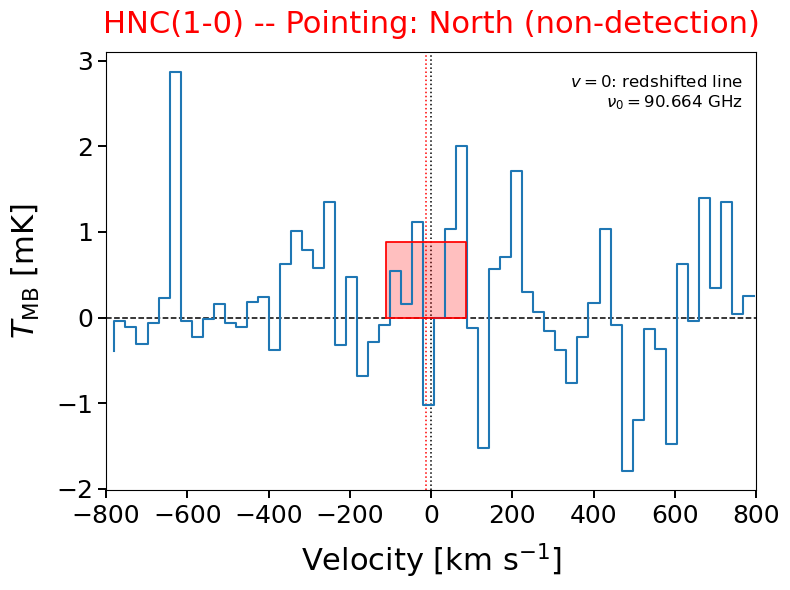

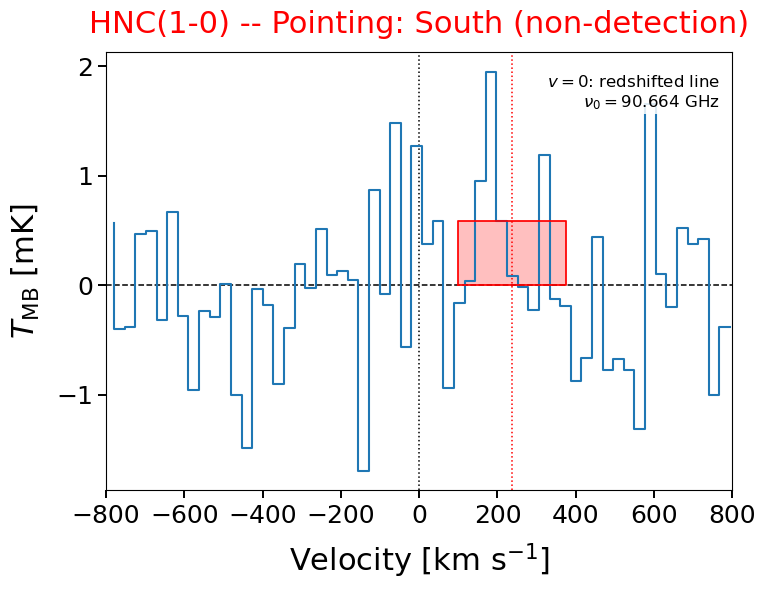

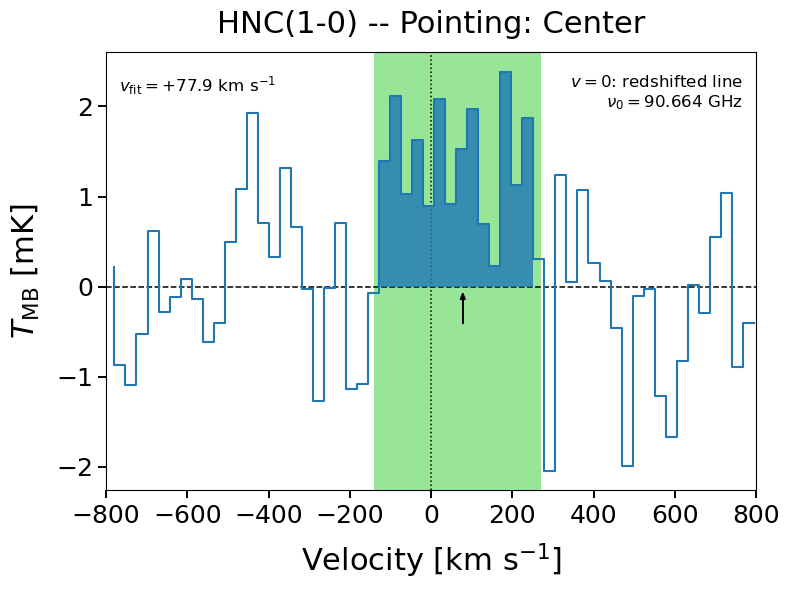

In [16]:
plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_NHNC_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HNC_fit_results.dat"),
    fuente="NGC3110_NOR",
    linea="HNC",
    line_label="HNC(1-0)",
    source_name="North",
    out_file=os.path.join(FIGURES_DIR, "NOR_HNC.png"),
    delta_vel=800,
    detected="no",
    upperlimits_file=os.path.join(BASE_DIR, "results", "ResultadosHNC", "upper_limit_HNC_2_results.dat"),
    tmb_unit="mK"
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_SHNC_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HNC_fit_results.dat"),
    fuente="NGC3110_SOU",
    linea="HNC",
    line_label="HNC(1-0)",
    source_name="South",
    out_file=os.path.join(FIGURES_DIR, "SOU_HNC.png"),
    delta_vel=800,
    detected="no",
    upperlimits_file=os.path.join(BASE_DIR, "results", "ResultadosHNC", "upper_limit_HNC_2_results.dat"),
    tmb_unit="mK"
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_CHNC_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HNC_fit_results.dat"),
    fuente="NGC3110_CEN",
    linea="HNC",
    line_label="HNC(1-0)",
    source_name="Center",
    out_file=os.path.join(FIGURES_DIR, "CEN_HNC.png"),
    delta_vel=800,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=2,
    extra_ch_right=1
)

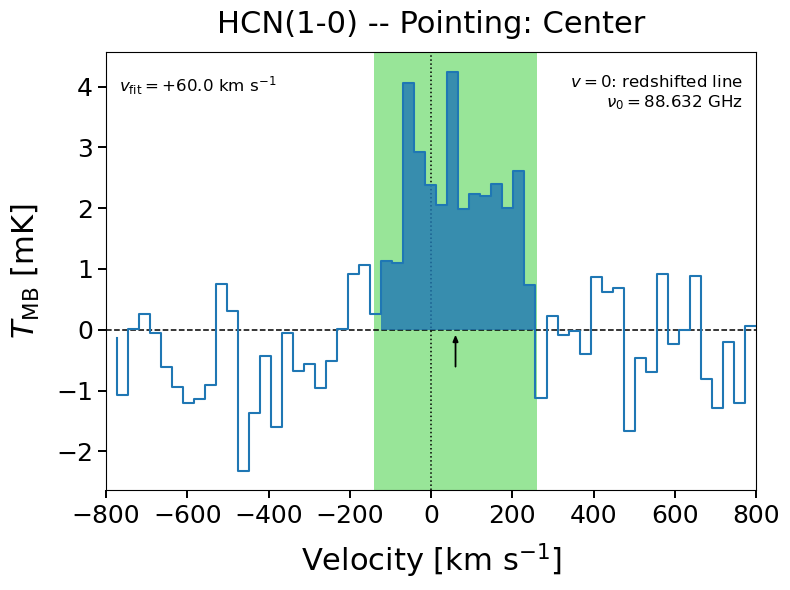

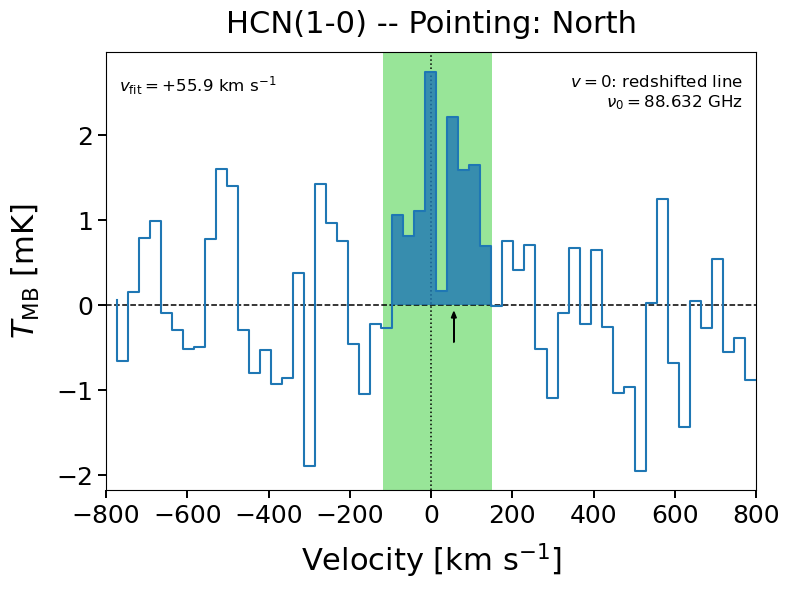

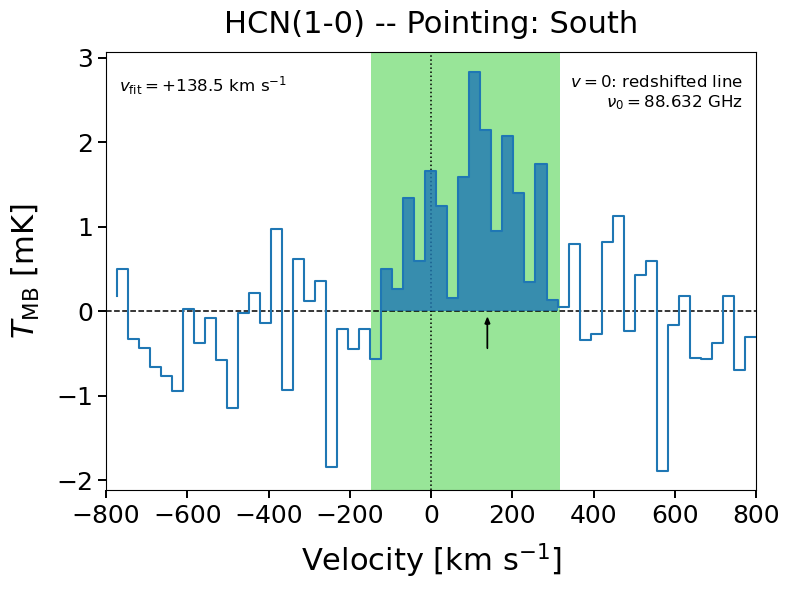

In [24]:
plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_CHCN_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCN_fit_results.dat"),
    fuente="NGC3110_CEN",
    linea="HCN",
    line_label="HCN(1-0)",
    source_name="Center",
    out_file=os.path.join(FIGURES_DIR, "CEN_HCN.png"),
    delta_vel=800,
    window_width=320,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=1,
    extra_ch_right=1
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_NHCN_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCN_fit_results.dat"),
    fuente="NGC3110_NOR",
    linea="HCN",
    line_label="HCN(1-0)",
    source_name="North",
    out_file=os.path.join(FIGURES_DIR, "NOR_HCN.png"),
    delta_vel=800,
    window_width=160,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=3,
    extra_ch_right=0
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_SHCN_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCN_fit_results.dat"),
    fuente="NGC3110_SOU",
    linea="HCN",
    line_label="HCN(1-0)",
    source_name="South",
    out_file=os.path.join(FIGURES_DIR, "SOU_HCN.png"),
    delta_vel=800,
    window_width=220,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=6,
    extra_ch_right=2
)

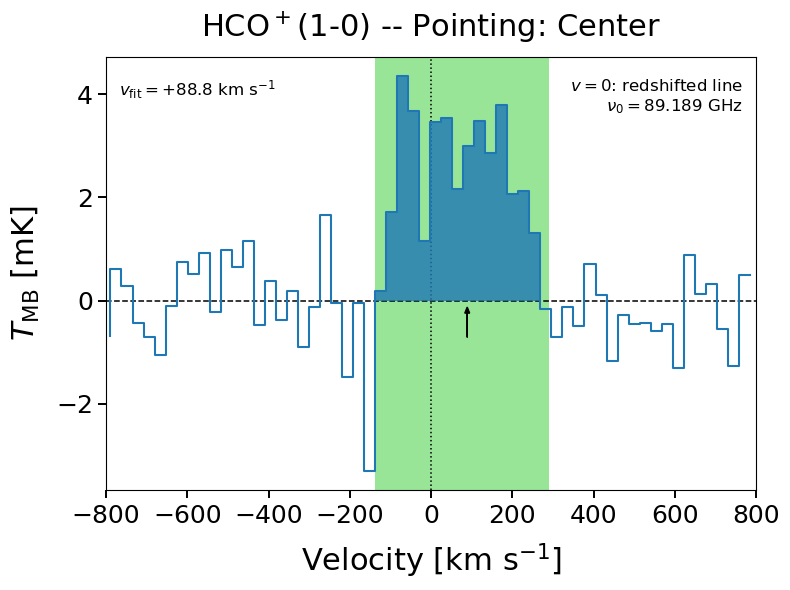

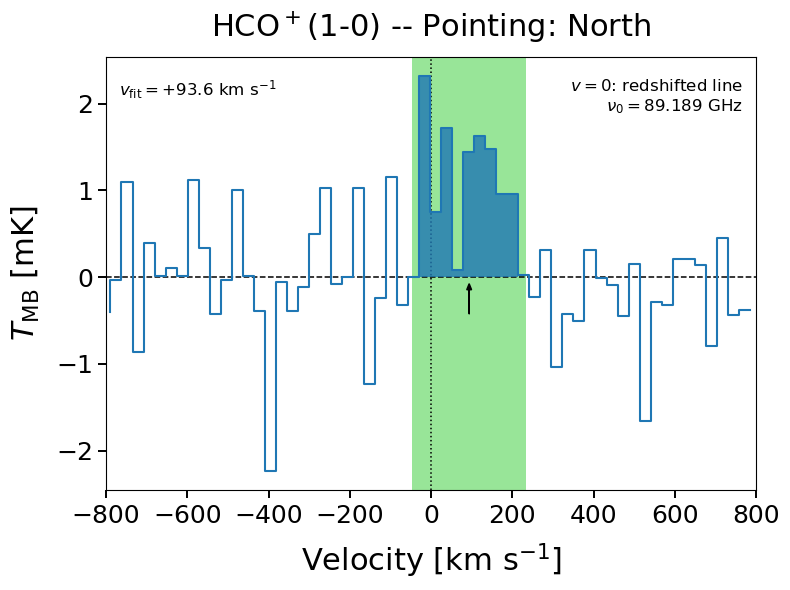

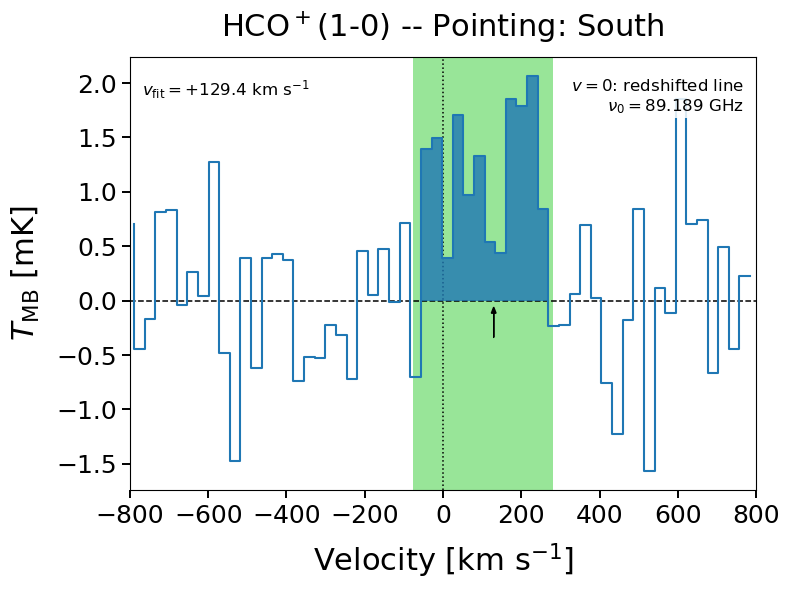

In [28]:
plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_CHCO_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCO_fit_results.dat"),
    fuente="NGC3110_CEN",
    linea="HCO",
    line_label=r"HCO$^+$(1-0)",
    source_name="Center",
    out_file=os.path.join(FIGURES_DIR, "CEN_HCO.png"),
    delta_vel=800,
    window_width=320,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=2,
    extra_ch_right=1
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_NHCO_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCO_fit_results.dat"),
    fuente="NGC3110_NOR",
    linea="HCO",
    line_label=r"HCO$^+$(1-0)",
    source_name="North",
    out_file=os.path.join(FIGURES_DIR, "NOR_HCO.png"),
    delta_vel=800,
    window_width=200,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=1,
    extra_ch_right=1
)

plot_spectrum_Dense(
    dat_file=os.path.join(SPECTRA_DIR, "W_SHCO_spectrum.dat"),
    results_file=os.path.join(RESULTS_CLASS_DIR, "W_HCO_fit_results.dat"),
    fuente="NGC3110_SOU",
    linea="HCO",
    line_label=r"HCO$^+$(1-0)",
    source_name="South",
    out_file=os.path.join(FIGURES_DIR, "SOU_HCO.png"),
    delta_vel=800,
    window_width=220,
    detected="yes",
    tmb_unit="mK",
    extra_ch_left=3,
    extra_ch_right=1
)